# EDA — Exploratory Data Analysis
### Data Science Core Concepts 101 — by Yunhan Jin

EDA is the first thing you do after getting data. The goal is to understand what you have before modeling anything.

This notebook follows a standardized EDA pipeline — the same sequence every data scientist runs on a new dataset:

1. Shape & Schema
2. Data Quality (missing values, duplicates, type fixes)
3. Numeric Distributions (continuous and discrete)
4. Categorical Distributions (nominal, ordinal, binary, high cardinality)
5. Datetime Analysis
6. Relationships
7. Target Variable

---

## Setup

### Loading Data
In practice, data comes from files. `pandas` handles the most common formats.

In [1]:
# CSV — most common format in DS
# df = pd.read_csv('housing.csv')

# Excel
# df = pd.read_excel('housing.xlsx', sheet_name='Sheet1')

# JSON
# df = pd.read_json('housing.json')

# From a SQL query
# df = pd.read_sql("SELECT * FROM table", conn)

# Save to CSV
# df.to_csv('output.csv', index=False)

print("Common loading patterns shown above — using synthetic dataset for this notebook.")

Common loading patterns shown above — using synthetic dataset for this notebook.


### Dataset
A synthetic housing dataset covering all common variable types.

| Type | Subtype | Column(s) | Notes |
|---|---|---|---|
| Numeric | Continuous | `price`, `sqft` | Infinite possible values in a range |
| Numeric | Discrete | `bedrooms` | Countable integer values |
| Categorical | Nominal | `neighborhood` | No natural ordering |
| Categorical | Ordinal | `condition` | Poor → Fair → Good → Excellent |
| Categorical | Binary | `has_garage`, `sold` | Stored as 0/1 — common in databases |
| Datetime | String → datetime | `listing_date` | Very common real-world problem |

Missing values and duplicates are introduced intentionally.

In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 200

neighborhoods = ['Downtown', 'Midtown', 'Uptown', 'Suburbs']
base_prices   = {'Downtown': 800000, 'Midtown': 600000, 'Uptown': 500000, 'Suburbs': 350000}
conditions    = ['Poor', 'Fair', 'Good', 'Excellent']

records = []
for i in range(n):
    nbhd  = np.random.choice(neighborhoods)
    sqft  = max(600, int(np.random.normal(1500, 400)))
    price = int(base_prices[nbhd] + sqft * 150 + np.random.normal(0, 50000))
    year  = np.random.randint(2019, 2024)
    month = np.random.randint(1, 13)
    day   = np.random.randint(1, 28)
    records.append({
        'id':           i + 1,
        'price':        price,
        'sqft':         sqft,
        'bedrooms':     np.random.choice([1, 2, 3, 4, 5], p=[0.1, 0.25, 0.35, 0.2, 0.1]),
        'bathrooms':    np.random.choice([1.0, 1.5, 2.0, 2.5, 3.0]),
        'neighborhood': nbhd,
        'condition':    np.random.choice(conditions, p=[0.05, 0.20, 0.50, 0.25]),
        'year_built':   int(np.random.normal(1990, 20)),
        'has_garage':   np.random.choice([True, False], p=[0.6, 0.4]),
        'sold':         np.random.choice([0, 1], p=[0.3, 0.7]),
        'listing_date': f"{year}-{month:02d}-{day:02d}"
    })

df = pd.DataFrame(records)

# Introduce missing values
df.loc[np.random.choice(n, 15, replace=False), 'bathrooms']  = np.nan
df.loc[np.random.choice(n, 10, replace=False), 'year_built'] = np.nan
df.loc[np.random.choice(n, 8,  replace=False), 'condition']  = np.nan

# Introduce duplicate rows
df = pd.concat([df, df.sample(5, random_state=42)], ignore_index=True)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (205, 11)


,id,price,sqft,bedrooms,bathrooms,neighborhood,condition,year_built,has_garage,sold,listing_date
0,1,717621,1279,3,2.0,Uptown,Good,1972.0,False,0,2023-05-07
1,2,526776,1335,2,3.0,Suburbs,Good,2000.0,True,1,2022-05-01
2,3,801656,1399,5,1.0,Midtown,Poor,1966.0,True,1,2021-12-23
3,4,496164,1650,3,2.5,Suburbs,Fair,2012.0,True,0,2020-05-02
4,5,732847,1022,2,NaN,Midtown,Fair,2004.0,True,0,2022-02-06


### Visualization Libraries

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

---
## Step 1: Shape & Schema
The first thing you do with any new dataset — understand its size, column names, and data types.

In [4]:
df.head()

,id,price,sqft,bedrooms,bathrooms,neighborhood,condition,year_built,has_garage,sold,listing_date
0,1,717621,1279,3,2.0,Uptown,Good,1972.0,False,0,2023-05-07
1,2,526776,1335,2,3.0,Suburbs,Good,2000.0,True,1,2022-05-01
2,3,801656,1399,5,1.0,Midtown,Poor,1966.0,True,1,2021-12-23
3,4,496164,1650,3,2.5,Suburbs,Fair,2012.0,True,0,2020-05-02
4,5,732847,1022,2,NaN,Midtown,Fair,2004.0,True,0,2022-02-06


In [5]:
print(df.shape)
print()
print(df.dtypes)

(205, 11)

id                int64
price             int64
sqft              int64
bedrooms          int64
bathrooms       float64
neighborhood        str
condition           str
year_built      float64
has_garage         bool
sold              int64
listing_date        str
dtype: object


In [6]:
df.describe()

,id,price,sqft,bedrooms,bathrooms,year_built,sold
count,205.000000,2.050000e+02,205.000000,205.000000,189.000000,195.000000,205.000000
mean,100.151220,7.960972e+05,1582.404878,2.892683,1.939153,1990.164103,0.678049
std,57.855902,1.791525e+05,424.824378,1.042337,0.694010,19.035337,0.468368
min,1.000000,4.072450e+05,600.000000,1.000000,1.000000,1936.000000,0.000000
25%,50.000000,6.652850e+05,1259.000000,2.000000,1.500000,1978.000000,0.000000
50%,100.000000,7.889170e+05,1556.000000,3.000000,2.000000,1991.000000,1.000000
75%,150.000000,9.214830e+05,1911.000000,4.000000,2.500000,2002.000000,1.000000
max,200.000000,1.205071e+06,2529.000000,5.000000,3.000000,2037.000000,1.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            205 non-null    int64  
 1   price         205 non-null    int64  
 2   sqft          205 non-null    int64  
 3   bedrooms      205 non-null    int64  
 4   bathrooms     189 non-null    float64
 5   neighborhood  205 non-null    str    
 6   condition     197 non-null    str    
 7   year_built    195 non-null    float64
 8   has_garage    205 non-null    bool   
 9   sold          205 non-null    int64  
 10  listing_date  205 non-null    str    
dtypes: bool(1), float64(2), int64(5), str(3)
memory usage: 20.9 KB


---
## Step 2: Data Quality
Fix what's broken before doing any analysis. Order matters: missing values first, then duplicates, then type fixes.

### 2.1 Missing Values
Always quantify missingness before deciding how to handle it.

In [8]:
missing = pd.DataFrame({
    'count': df.isnull().sum(),
    'pct':   (df.isnull().sum() / len(df) * 100).round(1)
})
missing[missing['count'] > 0]

,count,pct
bathrooms,16,7.8
condition,8,3.9
year_built,10,4.9


In [9]:
# How much is missing matters — it shapes your decision:
# < 5%  : safe to fill or drop
# 5-20% : fill with median/mean/mode, or use a model that handles NaN natively
# > 20% : keep as-is and use a tree-based model (XGBoost, LightGBM, CatBoost)
#          that handles NaN natively — better than filling with noise
# > 50% : consider dropping the column entirely

# Option 1: fill with a summary statistic
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].median())

# Option 2: drop rows missing a specific column
df = df.dropna(subset=['year_built']).reset_index(drop=True)

# Option 3: keep NaN as-is, use a tree-based model that handles it natively
# e.g. XGBoost, LightGBM, CatBoost — no imputation needed
# df_model = df.copy()  # pass directly to model

print(f"Shape after handling missing values: {df.shape}")

Shape after handling missing values: (195, 11)


### 2.2 Duplicates
Duplicate rows silently distort aggregations, model training, and train/test splits.

In [10]:
print(f"Duplicate rows: {df.duplicated().sum()}")

df = df.drop_duplicates().reset_index(drop=True)
print(f"After dedup: {df.shape}")

Duplicate rows: 5
After dedup: (190, 11)


### 2.3 Type Fixes
Columns often arrive as the wrong type. Three common cases:
- **Float with NaN that should be int**: use `Int64` (pandas nullable integer) — regular `int64` cannot hold NaN
- **Integer that should be bool**: `0/1` columns from databases should be cast to `bool`
- **String that should be datetime**: extremely common — databases often export dates as strings

**Gotcha**: watch for numeric columns that should actually be categorical — e.g. `zip_code` stored as an integer. A mean zip code is meaningless. Always check whether a numeric column represents a true quantity or just an ID/label.

In [11]:
# year_built has NaN — Int64 (pandas nullable integer) supports NaN; int64 does not
df['year_built'] = df['year_built'].astype('Int64')

# sold is stored as 0/1 integer — cast to bool
df['sold'] = df['sold'].astype(bool)

# listing_date is a string — convert to datetime
df['listing_date'] = pd.to_datetime(df['listing_date'])

df.dtypes

id                       int64
price                    int64
sqft                     int64
bedrooms                 int64
bathrooms              float64
neighborhood               str
condition                  str
year_built               Int64
has_garage                bool
sold                      bool
listing_date    datetime64[us]
dtype: object

---
## Step 3: Numeric Distributions
Numeric variables split into two subtypes:
- **Continuous**: infinite possible values within a range (`price`, `sqft`) — use histograms and boxplots
- **Discrete**: countable integer values (`bedrooms`) — use bar charts

### 3.1 Continuous

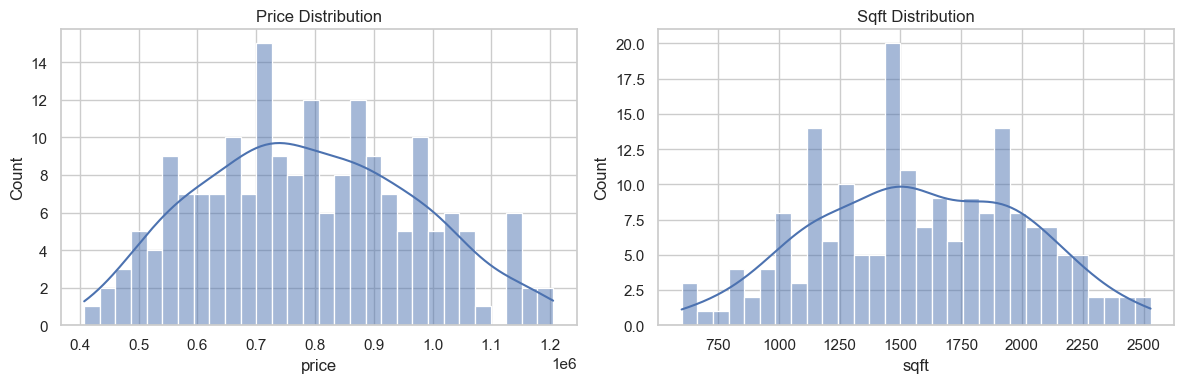

In [12]:
# Histogram — distribution shape, skew, and spread
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Price Distribution')
sns.histplot(df['sqft'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Sqft Distribution')
plt.tight_layout()
plt.show()

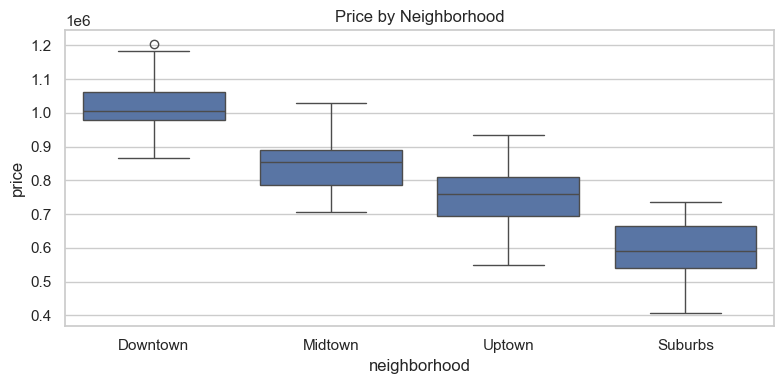

In [13]:
# Boxplot — spread, median, and outliers across groups
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='neighborhood', y='price',
            order=['Downtown', 'Midtown', 'Uptown', 'Suburbs'])
plt.title('Price by Neighborhood')
plt.tight_layout()
plt.show()

In [14]:
# Outlier detection — IQR method
Q1  = df['price'].quantile(0.25)
Q3  = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower    = Q1 - 1.5 * IQR
upper    = Q3 + 1.5 * IQR
outliers = df[(df['price'] < lower) | (df['price'] > upper)]

print(f"Outliers: {len(outliers)} rows ({len(outliers)/len(df)*100:.1f}%)")
print(f"Expected price range: ${lower:,.0f} — ${upper:,.0f}")

Outliers: 0 rows (0.0%)
Expected price range: $264,580 — $1,311,492


### 3.2 Discrete
Discrete numeric variables have a limited set of integer values. Use bar charts instead of histograms — each bar represents an exact count, not a bin range.

bedrooms
1    16
2    50
3    74
4    37
5    13
Name: count, dtype: int64


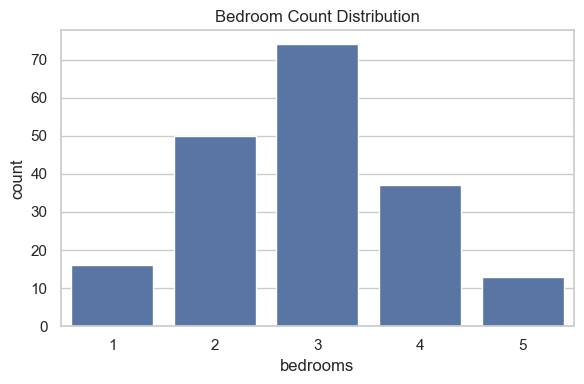

In [15]:
print(df['bedrooms'].value_counts().sort_index())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='bedrooms', order=sorted(df['bedrooms'].unique()))
plt.title('Bedroom Count Distribution')
plt.tight_layout()
plt.show()

---
## Step 4: Categorical Distributions
Categorical variables have three subtypes:
- **Nominal**: no natural ordering (`neighborhood`)
- **Ordinal**: has a meaningful order (`condition`: Poor → Fair → Good → Excellent)
- **Binary**: two possible values (`has_garage`, `sold`)

The key difference: ordinal variables require you to explicitly define and preserve the order — otherwise sorting alphabetically gives misleading results.

### 4.1 Nominal
No ordering — just counts and proportions.

In [16]:
print(df['neighborhood'].value_counts())

# Check for inconsistent labels — typos, casing, unexpected values
print(df['neighborhood'].unique())

# In real data you'd fix issues like:
# df['neighborhood'] = df['neighborhood'].str.strip().str.title()

neighborhood
Suburbs     58
Uptown      46
Downtown    46
Midtown     40
Name: count, dtype: int64
<ArrowStringArray>
['Uptown', 'Suburbs', 'Midtown', 'Downtown']
Length: 4, dtype: str


### 4.2 Ordinal
Has a meaningful order. Use `pd.Categorical` with `ordered=True` to define the ranking — this ensures sorting and plotting respect the order, not alphabetical.

condition
Poor          8
Fair         44
Good         81
Excellent    49
Name: count, dtype: int64


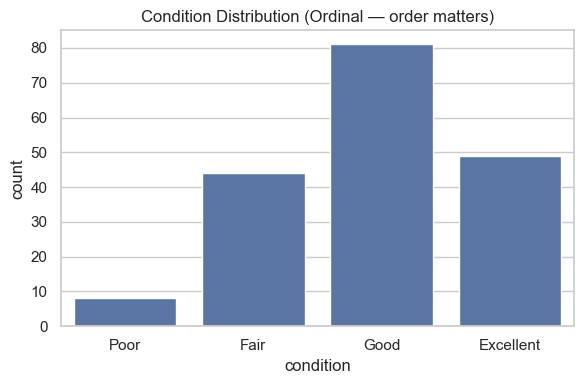

In [17]:
order = ['Poor', 'Fair', 'Good', 'Excellent']
df['condition'] = pd.Categorical(df['condition'], categories=order, ordered=True)

print(df['condition'].value_counts().reindex(order))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='condition', order=order)
plt.title('Condition Distribution (Ordinal — order matters)')
plt.tight_layout()
plt.show()

### 4.3 Binary
Two possible values. Simple value counts and proportion are enough.

In [18]:
print("has_garage:")
print(df['has_garage'].value_counts())
print()
print("sold:")
print(df['sold'].value_counts())

has_garage:
has_garage
True     115
False     75
Name: count, dtype: int64

sold:
sold
True     128
False     62
Name: count, dtype: int64


### 4.4 High Cardinality
When a categorical column has hundreds or thousands of unique values (e.g. `agent_id`, `zip_code`), `value_counts()` becomes unwieldy. Common approaches:
- Look at the top N values only: `df['col'].value_counts().head(20)`
- Check if the distribution is uniform or dominated by a few values
- Group rare categories into an `'Other'` bucket before modeling

---
## Step 5: Datetime Analysis
Once a column is converted to datetime (done in Step 2), extract components to analyze trends and seasonality.

In [19]:
# Extract components from datetime
df['listing_year']  = df['listing_date'].dt.year
df['listing_month'] = df['listing_date'].dt.month
df['listing_dow']   = df['listing_date'].dt.day_name()  # day of week

df[['listing_date', 'listing_year', 'listing_month', 'listing_dow']].head()

,listing_date,listing_year,listing_month,listing_dow
0,2023-05-07,2023,5,Sunday
1,2022-05-01,2022,5,Sunday
2,2021-12-23,2021,12,Thursday
3,2020-05-02,2020,5,Saturday
4,2022-02-06,2022,2,Sunday


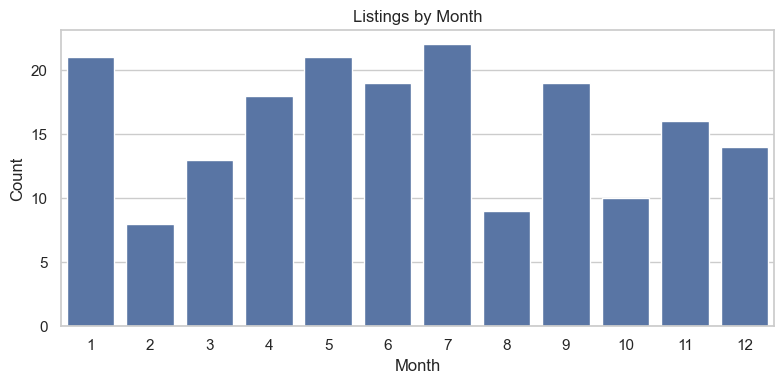

In [20]:
# Listings per month — spot seasonality
listings_by_month = df.groupby('listing_month').size()

plt.figure(figsize=(8, 4))
sns.barplot(x=listings_by_month.index, y=listings_by_month.values)
plt.title('Listings by Month')
plt.xlabel('Month')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

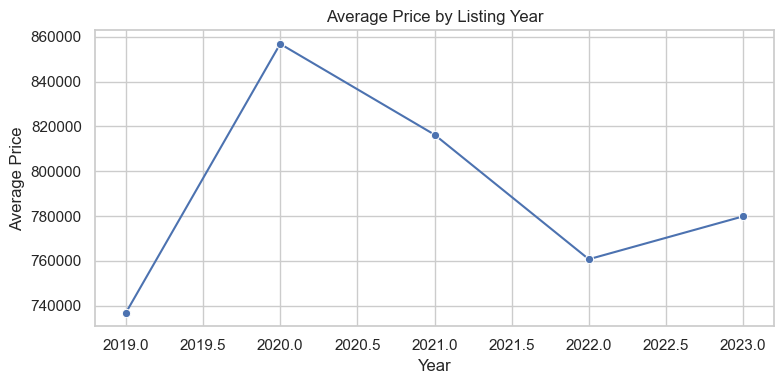

In [21]:
# Average price by year — spot trends over time
avg_price_year = df.groupby('listing_year')['price'].mean()

plt.figure(figsize=(8, 4))
sns.lineplot(x=avg_price_year.index, y=avg_price_year.values, marker='o')
plt.title('Average Price by Listing Year')
plt.xlabel('Year')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

---
## Step 6: Relationships
How do variables relate to each other? Look for correlations and patterns between features.

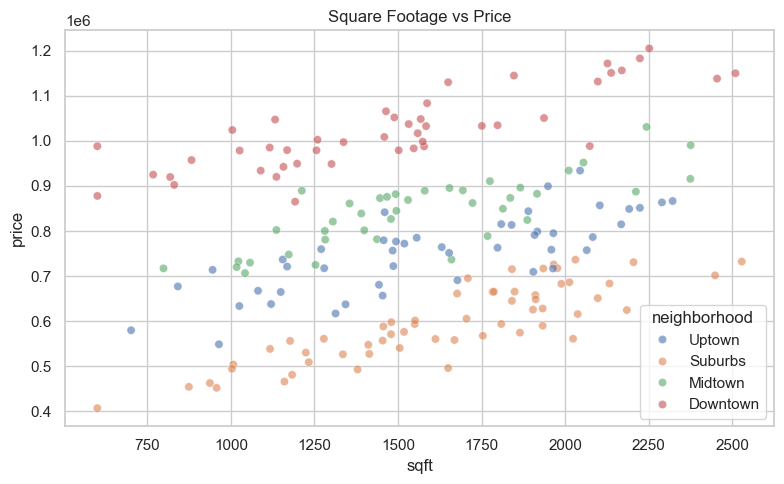

In [22]:
# Scatter — sqft vs price, colored by neighborhood
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='sqft', y='price', hue='neighborhood', alpha=0.6)
plt.title('Square Footage vs Price')
plt.tight_layout()
plt.show()

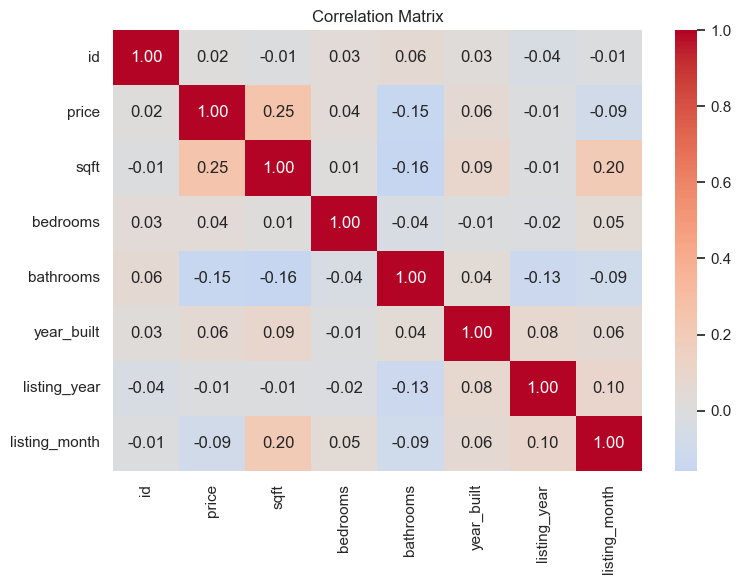

In [23]:
# Correlation heatmap — numeric columns only
numeric_cols = df.select_dtypes(include='number')

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_cols.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

---
## Step 7: Target Variable
If you're building a model, analyze the variable you're predicting. Understand its distribution and how it behaves across key features — this shapes every modeling decision downstream.

In this dataset, `price` is the target.

count    1.900000e+02
mean     7.886517e+05
std      1.805956e+05
min      4.072450e+05
25%      6.571722e+05
50%      7.803455e+05
75%      9.189002e+05
max      1.205071e+06
Name: price, dtype: float64


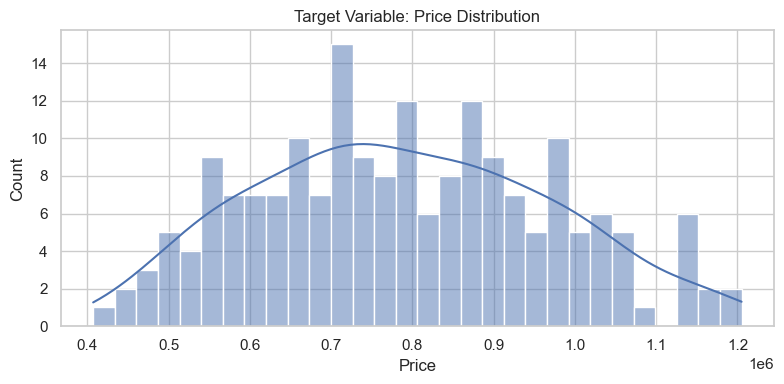

In [24]:
print(df['price'].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df['price'], bins=30, kde=True)
plt.title('Target Variable: Price Distribution')
plt.xlabel('Price')
plt.tight_layout()
plt.show()

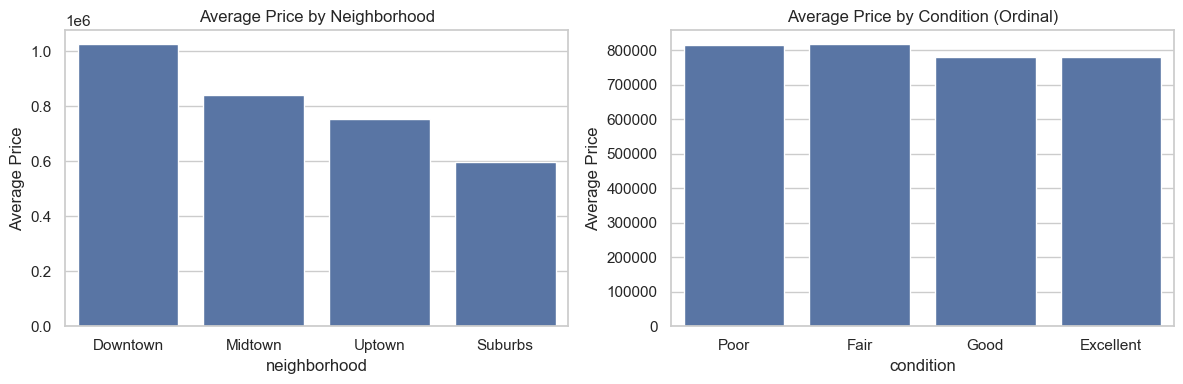

In [25]:
# Price by neighborhood and condition
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

avg_by_nbhd = df.groupby('neighborhood')['price'].mean().sort_values(ascending=False)
sns.barplot(x=avg_by_nbhd.index, y=avg_by_nbhd.values, ax=axes[0])
axes[0].set_title('Average Price by Neighborhood')
axes[0].set_ylabel('Average Price')

cond_order  = ['Poor', 'Fair', 'Good', 'Excellent']
avg_by_cond = df.groupby('condition', observed=True)['price'].mean().reindex(cond_order)
sns.barplot(x=avg_by_cond.index, y=avg_by_cond.values, ax=axes[1])
axes[1].set_title('Average Price by Condition (Ordinal)')
axes[1].set_ylabel('Average Price')

plt.tight_layout()
plt.show()

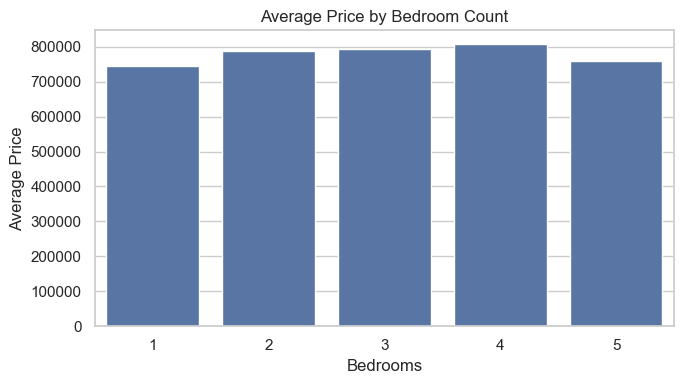

In [26]:
# Price by bedroom count
avg_price_bed = df.groupby('bedrooms')['price'].mean()

plt.figure(figsize=(7, 4))
sns.barplot(x=avg_price_bed.index, y=avg_price_bed.values)
plt.title('Average Price by Bedroom Count')
plt.xlabel('Bedrooms')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()